# TP - MLP para clasificación de texto (20 Newsgroups)
### Redes Neuronales / Deep Learning

Partimos de la notebook de Regresión Softmax y la extendemos a un **MLP** con búsqueda de hiperparámetros en Optuna (con **pruning**).

**Espacio de búsqueda** (todo dentro del mismo `objective`):

| Grupo | Hiperparámetros |
|---|---|
| Preprocesamiento / vectorización (TP anterior) | `remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df` |
| Entrenamiento (TP anterior) | `lr`, `batch_size` |
| Arquitectura | `n_layers` (1, 2 o 3), `units_l{i}` (neuronas por capa), `activation`, `dropout` |
| Optimizador | `optimizer` ∈ {SGD, RMSprop, Adam}; momento de 1er orden (`momentum` / `beta1`), momento de 2do orden (`alpha` de RMSprop / `beta2` de Adam), `weight_decay` |

**Plan**
1. Búsqueda con Optuna + `MedianPruner`.
2. Búsqueda dirigida de una configuración que **sobreajuste** (barrido de capas × neuronas, sin regularización).
3. Análisis transversal de todos los entrenamientos: performance, tiempos, gap train/val, importancia de HPs, efecto del pruning.
4. Entrenamiento final y evaluación en test (el test no se toca antes de esto).

## 0. Setup

In [ ]:
!pip install -q optuna

In [ ]:
import re, random, time, math, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
print("Usando dispositivo:", device)
if device.type == "cpu":
    print("ATENCION: estás en CPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU (acelera muchísimo).")

Usando dispositivo: cpu
ATENCION: estás en CPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU (acelera muchísimo).


In [ ]:
for pkg in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

## 1. Datos y preprocesamiento

Mismo dataset y mismo preprocesamiento que en el TP anterior (sin headers, footers ni quotes).

In [ ]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
y_all_train = np.array(newsgroups_train.target)
y_test = np.array(newsgroups_test.target)
print(f"Clases: {NUM_CLASSES} | Train: {len(newsgroups_train.data)} | Test: {len(newsgroups_test.data)}")

Clases: 20 | Train: 11314 | Test: 7532


In [ ]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)

def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

Igual que antes, precalculamos el preprocesamiento para las 6 combinaciones posibles (es la parte más lenta). Además cacheamos **la vectorización TF-IDF** por combinación de HPs, ya que el split train/val es fijo: si Optuna repite una combinación no se recalcula.

In [ ]:
preprocessed_cache = {}
for rm_sw in [False, True]:
    for norm in ["none", "stem", "lemmatize"]:
        tr = [preprocess_text(t, rm_sw, norm) for t in newsgroups_train.data]
        te = [preprocess_text(t, rm_sw, norm) for t in newsgroups_test.data]
        preprocessed_cache[(rm_sw, norm)] = (tr, te)
        print("  listo:", (rm_sw, norm))

  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [ ]:
# Split fijo train/val (el test NO se usa en la búsqueda)
idx_all = np.arange(len(y_all_train))
idx_tr, idx_val = train_test_split(idx_all, test_size=0.2, random_state=SEED, stratify=y_all_train)
y_tr, y_val = y_all_train[idx_tr], y_all_train[idx_val]

_vec_cache = {}
def get_vectorized(rm_sw, norm, ngram, max_features, min_df):
    """TF-IDF (sparse) del split train/val, con cache."""
    key = (rm_sw, norm, ngram, max_features, min_df)
    if key not in _vec_cache:
        texts, _ = preprocessed_cache[(rm_sw, norm)]
        tr_texts = [texts[i] for i in idx_tr]
        val_texts = [texts[i] for i in idx_val]
        ngram_t = (1, 1) if ngram == "1gram" else (1, 2)
        X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_t, max_features, min_df)
        _vec_cache[key] = (X_tr, X_val)
    return _vec_cache[key]

## 2. Modelo MLP, entrenamiento y optimizadores

- `MLP`: de 1 a 3 capas ocultas, activación configurable, dropout opcional. La salida son logits (`CrossEntropyLoss` aplica el softmax).
- El dataset entra entero en la GPU/CPU como tensor denso; los batches se arman con una permutación de índices (más rápido que un `DataLoader`).
- Se mide el **tiempo de entrenamiento** (con `cuda.synchronize` si hay GPU).
- `train_model` acepta un callback `on_epoch_end` que usamos para **reportar a Optuna y podar**.

In [ ]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "elu": nn.ELU,
    "gelu": nn.GELU,
    "silu": nn.SiLU,
    "tanh": nn.Tanh,
}

class MLP(nn.Module):
    def __init__(self, input_dim, hidden_units, num_classes, activation="relu", dropout=0.0):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_units:
            layers += [nn.Linear(prev, h), ACTIVATIONS[activation]()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def build_optimizer(params_model, name, lr, weight_decay=0.0, **kw):
    """
    SGD     : momentum (1er orden), nesterov
    RMSprop : alpha (decaimiento del 2do momento), momentum (1er orden)
    Adam    : beta1 (1er orden), beta2 (2do orden)
    """
    if name == "sgd":
        return optim.SGD(params_model, lr=lr, momentum=kw.get("momentum", 0.0),
                         nesterov=kw.get("nesterov", False), weight_decay=weight_decay)
    if name == "rmsprop":
        return optim.RMSprop(params_model, lr=lr, alpha=kw.get("alpha", 0.99),
                             momentum=kw.get("momentum", 0.0), weight_decay=weight_decay)
    if name == "adam":
        return optim.Adam(params_model, lr=lr, betas=(kw.get("beta1", 0.9), kw.get("beta2", 0.999)),
                          weight_decay=weight_decay)
    raise ValueError(name)


def to_dense(X):
    return torch.tensor(X.toarray(), dtype=torch.float32, device=device)

@torch.no_grad()
def evaluate(model, X, y, criterion, chunk=4096):
    model.eval()
    loss_sum, correct = 0.0, 0
    for i in range(0, X.size(0), chunk):
        xb, yb = X[i:i+chunk], y[i:i+chunk]
        logits = model(xb)
        loss_sum += criterion(logits, yb).item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
    return loss_sum / X.size(0), correct / X.size(0)

def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def train_model(model, optimizer, X_tr, y_tr, X_val, y_val, epochs, batch_size,
                on_epoch_end=None, verbose=False, tag="run", eval_train=True):
    """Devuelve history (dict de listas) y tiempo total de entrenamiento en segundos."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    n = X_tr.size(0)
    t_total = 0.0
    for epoch in range(epochs):
        _sync(); t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, batch_size):
            idx = perm[i:i+batch_size]
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            optimizer.step()
        _sync(); dt = time.perf_counter() - t0
        t_total += dt

        # En la búsqueda (eval_train=False) solo evaluamos train en la última época: ahorra un forward completo por época
        if eval_train or epoch == epochs - 1:
            tr_loss, tr_acc = evaluate(model, X_tr, y_tr, criterion)   # modo eval (sin dropout)
        else:
            tr_loss, tr_acc = float("nan"), float("nan")
        va_loss, va_acc = evaluate(model, X_val, y_val, criterion)
        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time"],
                        [tr_loss, va_loss, tr_acc, va_acc, dt]):
            hist[k].append(v)
        if verbose:
            print(f"[{tag}] ep {epoch+1:02d}/{epochs} train_loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val_loss {va_loss:.4f} acc {va_acc:.4f} | {dt:.2f}s")
        if on_epoch_end is not None:
            on_epoch_end(epoch, va_acc)   # puede levantar optuna.TrialPruned
    return hist, t_total

## 3. Búsqueda de hiperparámetros con Optuna + pruning

**Decisiones de diseño**
- El learning rate se muestrea con un nombre distinto por optimizador (`lr_sgd`, `lr_rmsprop`, `lr_adam`) porque el rango razonable es muy diferente (SGD tolera y necesita lr mucho mayores).
- Neuronas por capa: se muestrean **por capa** (`units_l1`, `units_l2`, `units_l3`), solo las que corresponden a `n_layers`.
- **Pruning**: en cada época se reporta `val_acc` con `trial.report`, y `MedianPruner` corta el trial si está por debajo de la mediana de los trials anteriores en esa misma época. Se evita así gastar épocas en configuraciones malas (por ejemplo SGD con lr muy chico o `tanh` mal inicializado).
- Se guardan como `user_attrs` el tiempo de entrenamiento, `train_acc`, `val_acc`, `val_loss` mínimo, mejor época, cantidad de parámetros y épocas efectivamente corridas, para el análisis posterior.

In [ ]:
MAX_EPOCHS_SEARCH = 8

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def sample_hparams(trial):
    hp = {}
    # --- TP anterior: preprocesamiento / vectorización ---
    hp["remove_stopwords"] = trial.suggest_categorical("remove_stopwords", [False, True])
    hp["normalization"]    = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    hp["ngram_range"]      = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    hp["max_features"]     = trial.suggest_categorical("max_features", [2000, 5000])
    hp["min_df"]           = trial.suggest_categorical("min_df", [1, 2, 5])
    hp["batch_size"]       = trial.suggest_categorical("batch_size", [128, 256, 512])
    # --- Arquitectura ---
    hp["n_layers"]   = trial.suggest_int("n_layers", 1, 3)
    hp["hidden"]     = [trial.suggest_categorical(f"units_l{i+1}", [32, 64, 128, 256, 512, 1024])
                        for i in range(hp["n_layers"])]
    hp["activation"] = trial.suggest_categorical("activation", list(ACTIVATIONS))
    hp["dropout"]    = trial.suggest_float("dropout", 0.0, 0.6)
    # --- Optimizador ---
    opt = trial.suggest_categorical("optimizer", ["sgd", "rmsprop", "adam"])
    hp["optimizer"] = opt
    hp["weight_decay"] = trial.suggest_float("weight_decay", 1e-8, 1e-2, log=True)
    if opt == "sgd":
        hp["lr"] = trial.suggest_float("lr_sgd", 1e-2, 3.0, log=True)
        hp["opt_kw"] = {"momentum": trial.suggest_float("sgd_momentum", 0.0, 0.99),
                        "nesterov": trial.suggest_categorical("sgd_nesterov", [False, True])}
    elif opt == "rmsprop":
        hp["lr"] = trial.suggest_float("lr_rmsprop", 1e-5, 1e-2, log=True)
        hp["opt_kw"] = {"alpha": trial.suggest_float("rms_alpha", 0.8, 0.999),            # 2do momento
                        "momentum": trial.suggest_float("rms_momentum", 0.0, 0.95)}       # 1er momento
    else:
        hp["lr"] = trial.suggest_float("lr_adam", 1e-5, 1e-2, log=True)
        hp["opt_kw"] = {"beta1": trial.suggest_float("adam_beta1", 0.8, 0.99),            # 1er momento
                        "beta2": trial.suggest_float("adam_beta2", 0.9, 0.9999)}          # 2do momento
    return hp

In [ ]:
def objective(trial):
    hp = sample_hparams(trial)
    set_seed(SEED + trial.number)

    X_tr_sp, X_val_sp = get_vectorized(hp["remove_stopwords"], hp["normalization"], hp["ngram_range"],
                                       hp["max_features"], hp["min_df"])
    X_tr, X_val = to_dense(X_tr_sp), to_dense(X_val_sp)
    yt = torch.tensor(y_tr, dtype=torch.long, device=device)
    yv = torch.tensor(y_val, dtype=torch.long, device=device)

    model = MLP(X_tr.shape[1], hp["hidden"], NUM_CLASSES, hp["activation"], hp["dropout"]).to(device)
    optimizer = build_optimizer(model.parameters(), hp["optimizer"], hp["lr"], hp["weight_decay"], **hp["opt_kw"])
    trial.set_user_attr("n_params", count_params(model))

    state = {"epochs": 0, "best": 0.0, "best_ep": 0}
    t_start = time.perf_counter()

    def on_epoch_end(epoch, val_acc):
        state["epochs"] = epoch + 1
        if val_acc > state["best"]:
            state["best"], state["best_ep"] = val_acc, epoch + 1
        trial.set_user_attr("epochs_run", state["epochs"])
        trial.set_user_attr("wall_time", time.perf_counter() - t_start)
        trial.report(val_acc, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    try:
        hist, t_train = train_model(model, optimizer, X_tr, yt, X_val, yv, MAX_EPOCHS_SEARCH,
                                    hp["batch_size"], on_epoch_end=on_epoch_end, tag=f"trial_{trial.number}",
                                    eval_train=False)
    finally:
        trial.set_user_attr("wall_time", time.perf_counter() - t_start)
        del X_tr, X_val
        if device.type == "cuda":
            torch.cuda.empty_cache()

    best_ep = int(np.argmax(hist["val_acc"]))
    trial.set_user_attr("train_time", t_train)
    trial.set_user_attr("best_epoch", best_ep + 1)
    trial.set_user_attr("train_acc", hist["train_acc"][-1])   # train_acc en la última época (solo se evalúa ahí)
    trial.set_user_attr("min_val_loss", float(np.min(hist["val_loss"])))
    trial.set_user_attr("final_val_loss", hist["val_loss"][-1])
    return max(hist["val_acc"])

In [ ]:
N_TRIALS = 40       # tope de trials
TIMEOUT_MIN = 25    # tope de tiempo: corta la búsqueda al llegar (los trials hechos se conservan)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=1, interval_steps=1),
    study_name="mlp_20newsgroups",
)
t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_MIN * 60, show_progress_bar=True)
SEARCH_WALL_TIME = time.perf_counter() - t0

print(f"\nTiempo total de búsqueda: {SEARCH_WALL_TIME/60:.1f} min")
print("Mejor val_acc:", round(study.best_value, 4))
print("Mejores hiperparámetros:")
for k, v in study.best_params.items():
    print(f"   {k}: {v}")

  0%|          | 0/40 [00:00<?, ?it/s]


Tiempo total de búsqueda: 4.3 min
Mejor val_acc: 0.7207
Mejores hiperparámetros:
   remove_stopwords: True
   normalization: stem
   ngram_range: 1_2gram
   max_features: 5000
   min_df: 2
   batch_size: 512
   n_layers: 1
   units_l1: 256
   activation: silu
   dropout: 0.2901954262044291
   optimizer: rmsprop
   weight_decay: 5.402202205879958e-08
   lr_rmsprop: 0.0009056597684546748
   rms_alpha: 0.8490468695179783
   rms_momentum: 0.7668281579273881


## 4. Encontrar una configuración que sobreajuste

Para forzar el overfitting: **sin regularización** (`dropout=0`, `weight_decay=0`), Adam con lr fijo, el mejor preprocesamiento/vectorización de la búsqueda (con `max_features=10000` para tener más entradas) y un **barrido de capacidad**: profundidad (1, 2, 3 capas) × ancho (neuronas por capa). Entrenamos 15 épocas y medimos:

- `train_acc` vs `val_acc` (gap),
- `val_loss` mínima vs final (si la val_loss sube mientras la train_loss sigue bajando, hay overfitting),
- cantidad de parámetros y tiempo.

Criterio de "overfiteado": `train_acc ≥ 0.99` y gap `train_acc − val_acc` grande, con `val_loss` final claramente por encima de su mínimo.

In [ ]:
bp = study.best_params
OV_PREP = dict(rm_sw=bp["remove_stopwords"], norm=bp["normalization"], ngram=bp["ngram_range"],
               max_features=10000, min_df=bp["min_df"])
X_tr_sp, X_val_sp = get_vectorized(OV_PREP["rm_sw"], OV_PREP["norm"], OV_PREP["ngram"],
                                   OV_PREP["max_features"], OV_PREP["min_df"])
X_tr_ov, X_val_ov = to_dense(X_tr_sp), to_dense(X_val_sp)
yt_ov = torch.tensor(y_tr, dtype=torch.long, device=device)
yv_ov = torch.tensor(y_val, dtype=torch.long, device=device)
print("Input dim:", X_tr_ov.shape[1])

OV_EPOCHS = 15
OV_WIDTHS = [64, 512, 2048]
OV_DEPTHS = [1, 2, 3]

ov_rows, ov_hist = [], {}
for depth in OV_DEPTHS:
    for width in OV_WIDTHS:
        set_seed()
        model = MLP(X_tr_ov.shape[1], [width] * depth, NUM_CLASSES, "relu", dropout=0.0)
        opt = build_optimizer(model.parameters(), "adam", 1e-3, weight_decay=0.0)
        hist, t_train = train_model(model, opt, X_tr_ov, yt_ov, X_val_ov, yv_ov, OV_EPOCHS, 64, tag=f"{depth}x{width}")
        be = int(np.argmin(hist["val_loss"]))
        ov_hist[(depth, width)] = hist
        ov_rows.append(dict(
            layers=depth, units=width, params=count_params(model),
            train_acc=hist["train_acc"][-1], val_acc=hist["val_acc"][-1], best_val_acc=max(hist["val_acc"]),
            gap=hist["train_acc"][-1] - hist["val_acc"][-1],
            train_loss=hist["train_loss"][-1], val_loss_final=hist["val_loss"][-1],
            val_loss_min=hist["val_loss"][be], epoch_min_val_loss=be + 1,
            val_loss_rise=hist["val_loss"][-1] - hist["val_loss"][be], time_s=t_train))
        r = ov_rows[-1]
        print(f"{depth}x{width:<5} params={r['params']/1e6:6.2f}M  train_acc={r['train_acc']:.3f} val_acc={r['val_acc']:.3f} "
              f"gap={r['gap']:.3f}  val_loss min@{r['epoch_min_val_loss']}={r['val_loss_min']:.3f} -> final={r['val_loss_final']:.3f}  {t_train:.0f}s")
df_ov = pd.DataFrame(ov_rows)
df_ov

Input dim: 10000
1x64    params=  0.64M  train_acc=0.973 val_acc=0.726 gap=0.247  val_loss min@10=0.900 -> final=0.928  14s
1x512   params=  5.13M  train_acc=0.973 val_acc=0.721 gap=0.251  val_loss min@4=0.887 -> final=1.052  80s
1x2048  params= 20.52M  train_acc=0.973 val_acc=0.715 gap=0.258  val_loss min@2=0.897 -> final=1.156  423s
2x64    params=  0.65M  train_acc=0.973 val_acc=0.659 gap=0.314  val_loss min@4=1.059 -> final=1.531  13s
2x512   params=  5.39M  train_acc=0.973 val_acc=0.707 gap=0.266  val_loss min@2=1.014 -> final=1.428  87s
2x2048  params= 24.72M  train_acc=0.973 val_acc=0.696 gap=0.277  val_loss min@1=1.011 -> final=1.554  565s
3x64    params=  0.65M  train_acc=0.972 val_acc=0.596 gap=0.376  val_loss min@3=1.433 -> final=2.833  14s
3x512   params=  5.66M  train_acc=0.973 val_acc=0.665 gap=0.307  val_loss min@2=1.179 -> final=2.156  93s
3x2048  params= 28.92M  train_acc=0.973 val_acc=0.675 gap=0.298  val_loss min@2=1.176 -> final=2.665  674s


,layers,units,params,train_acc,val_acc,best_val_acc,gap,train_loss,val_loss_final,val_loss_min,epoch_min_val_loss,val_loss_rise,time_s
0,1,64,641364,0.973042,0.726027,0.740610,0.247014,0.119653,0.927532,0.899819,10,0.027713,13.794464
1,1,512,5130772,0.972600,0.721167,0.742377,0.251433,0.089943,1.051690,0.887356,4,0.164334,79.885334
2,1,2048,20523028,0.973373,0.715422,0.733540,0.257951,0.089500,1.156054,0.897006,2,0.259048,423.044182
3,2,64,645524,0.972600,0.658860,0.686257,0.313740,0.093645,1.531446,1.059127,4,0.472319,12.880172
4,2,512,5393428,0.972600,0.706584,0.707910,0.266016,0.089123,1.428100,1.014183,2,0.413917,87.095945
5,2,2048,24719380,0.973373,0.696421,0.710119,0.276952,0.086409,1.554127,1.010578,1,0.543549,564.966394
6,3,64,649684,0.972158,0.596111,0.612019,0.376046,0.096648,2.833248,1.432862,3,1.400386,13.898881
7,3,512,5656084,0.972600,0.665488,0.666814,0.307111,0.086706,2.156056,1.178650,2,0.977406,92.972971
8,3,2048,28915732,0.973263,0.674768,0.674768,0.298495,0.086017,2.665033,1.176355,2,1.488678,673.516359


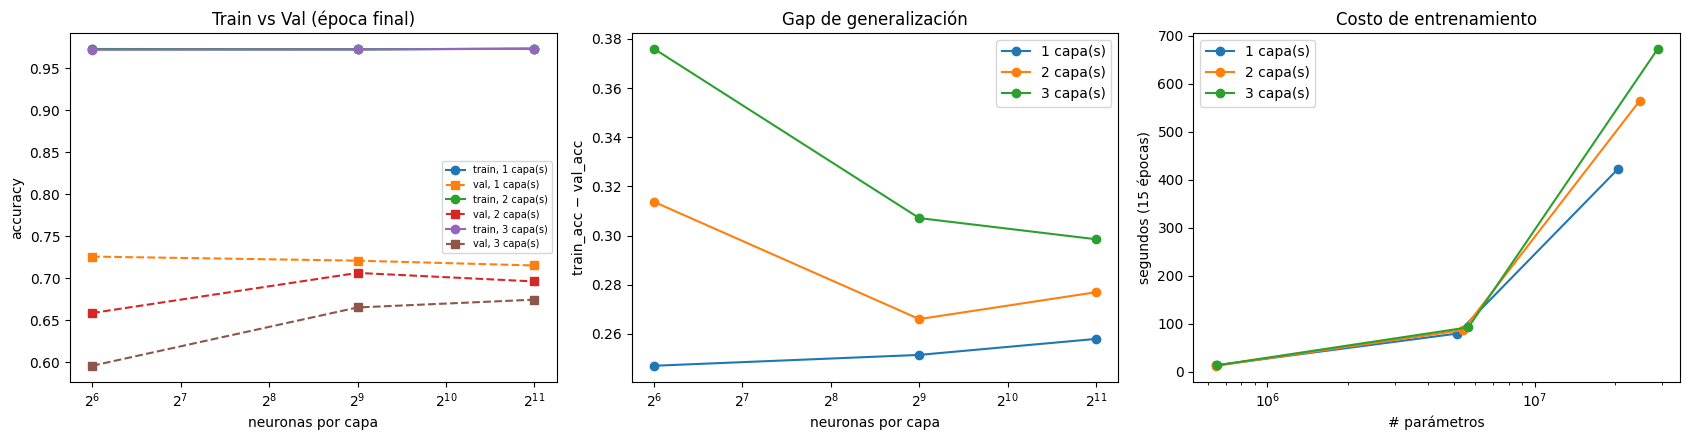

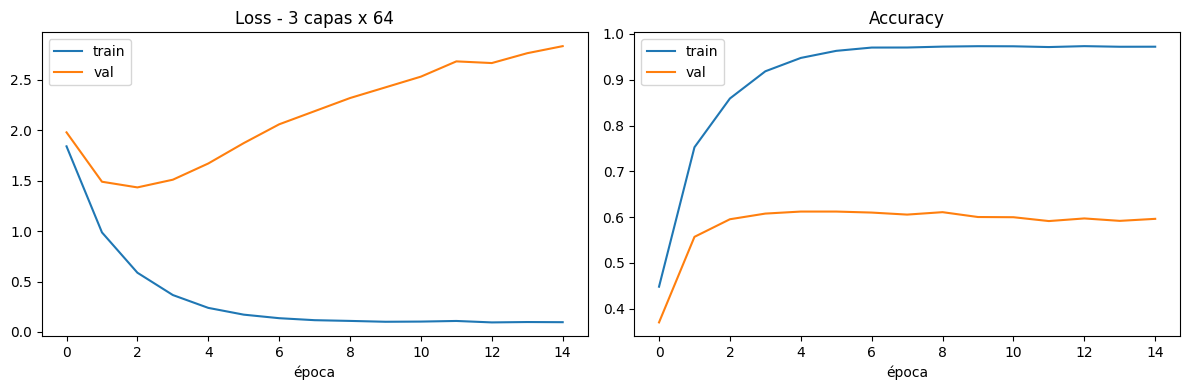

Configuración más sobreajustada: (3, 64) | train_acc = 0.972 | val_acc = 0.596


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for depth in OV_DEPTHS:
    d = df_ov[df_ov.layers == depth]
    axes[0].plot(d.units, d.train_acc, "o-", label=f"train, {depth} capa(s)")
    axes[0].plot(d.units, d.val_acc, "s--", label=f"val, {depth} capa(s)")
    axes[1].plot(d.units, d.gap, "o-", label=f"{depth} capa(s)")
    axes[2].plot(d.params, d.time_s, "o-", label=f"{depth} capa(s)")
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("neuronas por capa"); axes[0].set_ylabel("accuracy"); axes[0].set_title("Train vs Val (época final)"); axes[0].legend(fontsize=7)
axes[1].set_xscale("log", base=2); axes[1].set_xlabel("neuronas por capa"); axes[1].set_ylabel("train_acc − val_acc"); axes[1].set_title("Gap de generalización"); axes[1].legend()
axes[2].set_xscale("log"); axes[2].set_xlabel("# parámetros"); axes[2].set_ylabel("segundos (%d épocas)" % OV_EPOCHS); axes[2].set_title("Costo de entrenamiento"); axes[2].legend()
plt.tight_layout(); plt.show()

# Curvas de la configuración con mayor gap
worst = df_ov.sort_values("gap", ascending=False).iloc[0]
key = (int(worst.layers), int(worst.units))
h = ov_hist[key]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title(f"Loss - {key[0]} capas x {key[1]}"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["val_acc"], label="val"); ax[1].set_title("Accuracy"); ax[1].set_xlabel("época"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Configuración más sobreajustada:", key, "| train_acc =", round(worst.train_acc, 3), "| val_acc =", round(worst.val_acc, 3))

In [ ]:
# Config que cumple el criterio de overfitting y es la más chica (menos parámetros)
cand = df_ov[(df_ov.train_acc >= 0.99) & (df_ov.val_loss_rise > 0.05)].sort_values("params")
print("Configuraciones que cumplen el criterio de overfitting (ordenadas por tamaño):")
display(cand[["layers", "units", "params", "train_acc", "val_acc", "gap", "val_loss_min", "val_loss_final", "time_s"]])
del X_tr_ov, X_val_ov
if device.type == "cuda": torch.cuda.empty_cache()

Configuraciones que cumplen el criterio de overfitting (ordenadas por tamaño):


,layers,units,params,train_acc,val_acc,gap,val_loss_min,val_loss_final,time_s


## 5. Análisis transversal de todos los entrenamientos

Juntamos todos los trials en un DataFrame (completados + podados) y comparamos performance, tiempos y regularización.

In [ ]:
df = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
df.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df.columns]
df["state"] = df["state"].astype(str).str.replace("TrialState.", "", regex=False)
df["n_layers"] = df["n_layers"].astype(int)
df["arch"] = df.apply(lambda r: "-".join(str(int(r[f"units_l{i+1}"])) for i in range(r["n_layers"])), axis=1)

done = df[df.state == "COMPLETE"].copy()
done["gap"] = done["train_acc"] - done["value"]
print(df.state.value_counts().to_string())
print(f"\nTrials: {len(df)} | completos: {len(done)} | podados: {(df.state=='PRUNED').sum()}")

cols = ["number", "value", "train_acc", "gap", "optimizer", "activation", "n_layers", "arch", "dropout",
        "weight_decay", "batch_size", "n_params", "train_time", "best_epoch"]
print("\nTop 10 por val_acc:")
display(done.sort_values("value", ascending=False)[cols].head(10).round(4))

state
COMPLETE    23
PRUNED      17

Trials: 40 | completos: 23 | podados: 17

Top 10 por val_acc:


,number,value,train_acc,gap,optimizer,activation,n_layers,arch,dropout,weight_decay,batch_size,n_params,train_time,best_epoch
39,39,0.7207,0.9438,0.2230,rmsprop,silu,1,256,0.2902,0.0,512,1285396,5.9778,7.0
32,32,0.7035,0.9716,0.2681,rmsprop,silu,1,256,0.2322,0.0,512,1285396,5.7206,2.0
26,26,0.7030,0.9654,0.2624,rmsprop,silu,1,256,0.2292,0.0,128,1285396,8.0038,2.0
36,36,0.6995,0.9300,0.2304,rmsprop,silu,1,64,0.3141,0.0,128,321364,2.7128,6.0
38,38,0.6995,0.9504,0.2509,rmsprop,silu,1,256,0.4359,0.0,128,1285396,8.3540,5.0
23,23,0.6916,0.9704,0.2788,rmsprop,silu,1,256,0.0017,0.0,512,1285396,5.9256,3.0
34,34,0.6902,0.9698,0.2796,rmsprop,silu,1,64,0.2041,0.0,128,321364,2.8015,2.0
33,33,0.6898,0.9708,0.2810,rmsprop,silu,1,128,0.0390,0.0,512,642708,3.5654,2.0
27,27,0.6836,0.9655,0.2819,rmsprop,silu,1,256,0.3019,0.0,512,1285396,6.1415,1.0
31,31,0.6770,0.9682,0.2912,rmsprop,tanh,1,256,0.2358,0.0,512,1285396,5.7185,1.0


### 5.1 Efecto del pruning en tiempo

Épocas ejecutadas: 220 de 320 posibles sin pruning (69%)
Tiempo real en trials: 3.2 min | ahorro estimado por pruning: ~1.5 min


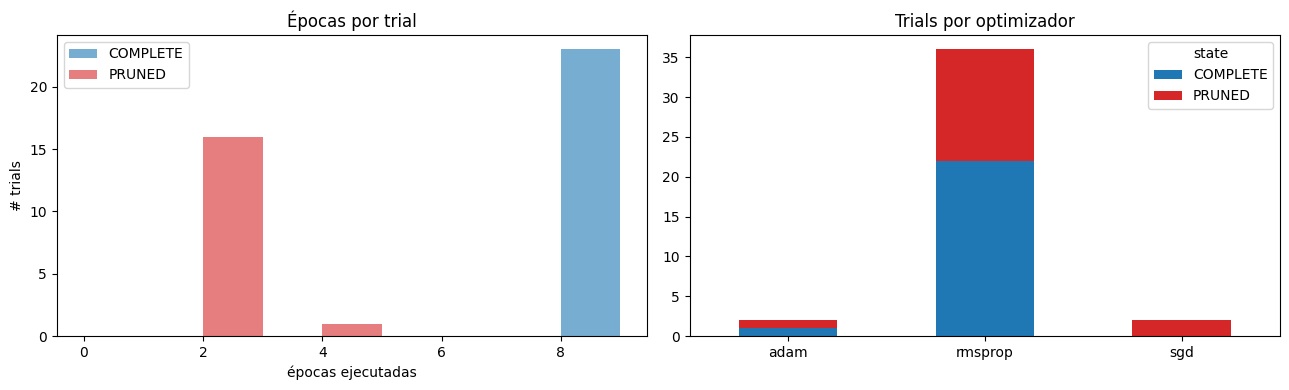

In [ ]:
pr = df[df.state == "PRUNED"]
epochs_used = df["epochs_run"].fillna(0)
epochs_if_no_prune = len(df) * MAX_EPOCHS_SEARCH
print(f"Épocas ejecutadas: {int(epochs_used.sum())} de {epochs_if_no_prune} posibles sin pruning "
      f"({100*epochs_used.sum()/epochs_if_no_prune:.0f}%)")

# Estimación del tiempo ahorrado: tiempo por época promedio * épocas evitadas
t_train_all = df["wall_time"].sum()
sec_per_epoch = t_train_all / max(epochs_used.sum(), 1)
saved = sec_per_epoch * (epochs_if_no_prune - epochs_used.sum())
print(f"Tiempo real en trials: {t_train_all/60:.1f} min | ahorro estimado por pruning: ~{saved/60:.1f} min")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for state, color in [("COMPLETE", "tab:blue"), ("PRUNED", "tab:red")]:
    d = df[df.state == state]
    ax[0].hist(d["epochs_run"], bins=range(0, MAX_EPOCHS_SEARCH + 2), alpha=.6, label=state, color=color)
ax[0].set_xlabel("épocas ejecutadas"); ax[0].set_ylabel("# trials"); ax[0].legend(); ax[0].set_title("Épocas por trial")
pd.crosstab(df.optimizer, df.state).plot.bar(stacked=True, ax=ax[1], color={"COMPLETE": "tab:blue", "PRUNED": "tab:red"}, rot=0)
ax[1].set_title("Trials por optimizador"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

### 5.2 Performance y tiempo por optimizador, activación y profundidad

In [ ]:
def summarize(by):
    g = done.groupby(by)
    out = pd.DataFrame({
        "trials_completos": g.size(),
        "val_acc_media": g["value"].mean(),
        "val_acc_max": g["value"].max(),
        "gap_medio": g["gap"].mean(),
        "tiempo_medio_s": g["train_time"].mean(),
        "params_medios": g["n_params"].mean(),
    })
    tot = df.groupby(by).size().rename("trials_totales")
    pruned = df[df.state == "PRUNED"].groupby(by).size().rename("podados")
    return out.join(tot, how="outer").join(pruned, how="left").fillna({"podados": 0}).sort_values("val_acc_max", ascending=False).round(4)

for by in ["optimizer", "activation", "n_layers"]:
    print(f"\n=== por {by} ===")
    display(summarize(by))


=== por optimizer ===


,trials_completos,val_acc_media,val_acc_max,gap_medio,tiempo_medio_s,params_medios,trials_totales,podados
optimizer,,,,,,,,
rmsprop,22.0,0.6369,0.7207,0.2497,6.1724,1.071419e+06,36,14
adam,1.0,0.5506,0.5506,0.0607,16.3084,2.570772e+06,2,1
sgd,NaN,NaN,NaN,NaN,NaN,NaN,2,2



=== por activation ===


,trials_completos,val_acc_media,val_acc_max,gap_medio,tiempo_medio_s,params_medios,trials_totales,podados
activation,,,,,,,,
silu,13,0.6833,0.7207,0.2576,7.2596,1.325194e+06,19,6.0
tanh,3,0.6425,0.6770,0.2758,4.2640,6.942067e+05,6,3.0
leaky_relu,4,0.6073,0.6346,0.2343,6.6643,1.033892e+06,9,5.0
relu,1,0.5983,0.5983,0.0603,4.5441,1.034772e+06,4,3.0
gelu,2,0.3624,0.5904,0.1901,6.8668,8.307560e+05,2,0.0



=== por n_layers ===


,trials_completos,val_acc_media,val_acc_max,gap_medio,tiempo_medio_s,params_medios,trials_totales,podados
n_layers,,,,,,,,
1,19,0.6614,0.7207,0.2476,7.0780,1.273054e+06,24,5
2,2,0.6217,0.6332,0.2752,3.1307,4.026120e+05,8,6
3,2,0.3758,0.6173,0.1492,5.6784,5.743720e+05,8,6


/tmp/ipykernel_5424/320890744.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([done[done[by] == g]["value"] for g in groups], labels=[str(g) for g in groups])
/tmp/ipykernel_5424/320890744.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([done[done[by] == g]["value"] for g in groups], labels=[str(g) for g in groups])
/tmp/ipykernel_5424/320890744.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([done[done[by] == g]["value"] for g in groups], labels=[str(g) for g in groups])


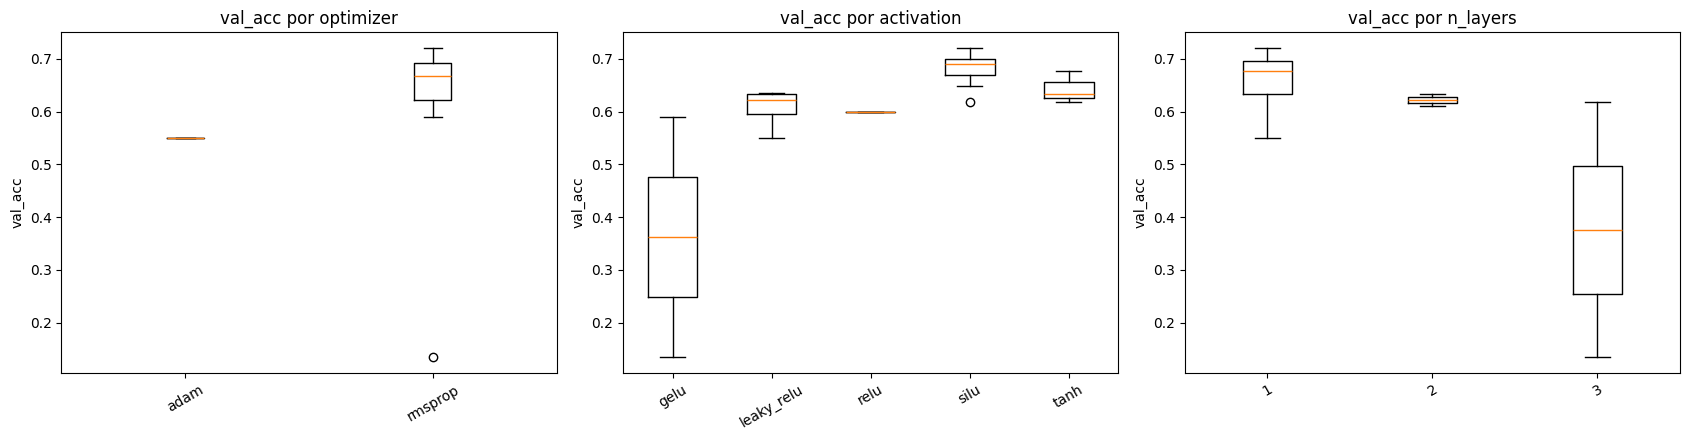

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, by in zip(axes, ["optimizer", "activation", "n_layers"]):
    groups = sorted(done[by].unique(), key=str)
    ax.boxplot([done[done[by] == g]["value"] for g in groups], labels=[str(g) for g in groups])
    ax.set_title(f"val_acc por {by}"); ax.set_ylabel("val_acc"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 5.3 Performance vs tiempo de entrenamiento y tamaño del modelo

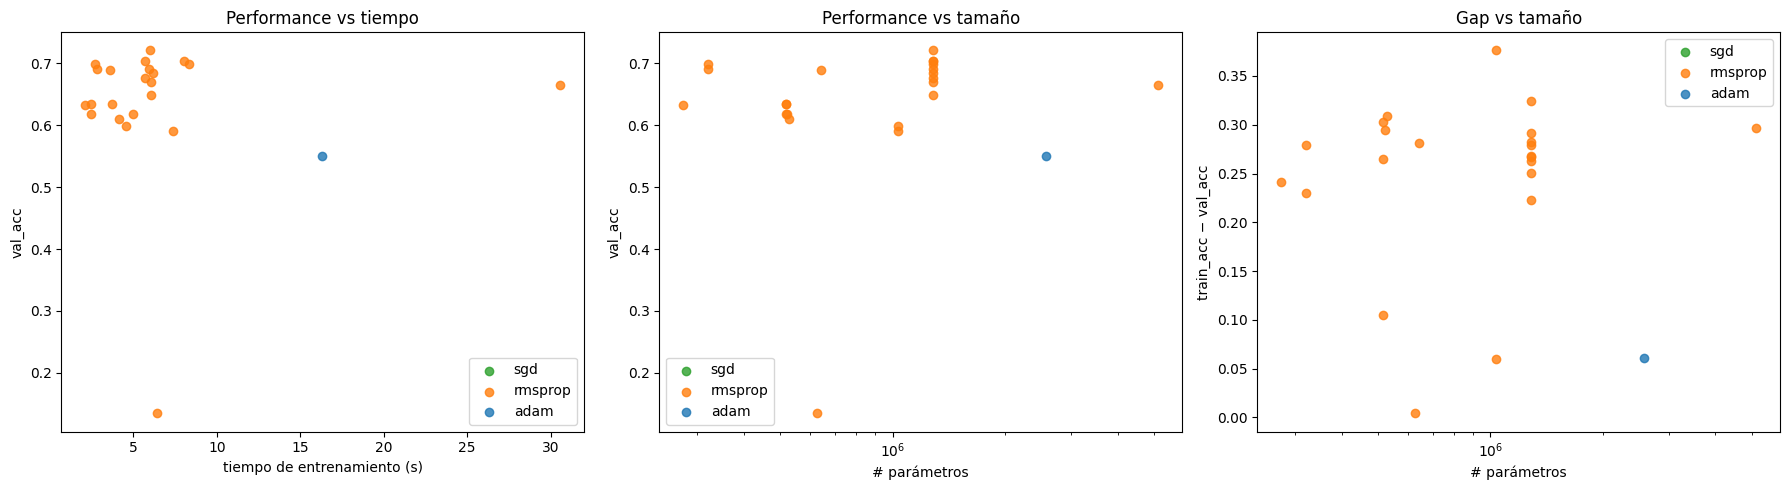

Trials en la frontera de Pareto (tiempo vs val_acc):


,number,value,train_time,optimizer,activation,arch,n_params
17,17,0.6332,2.1051,rmsprop,tanh,128-128,275220
20,20,0.6337,2.4789,rmsprop,leaky_relu,256,517396
32,32,0.7035,5.7206,rmsprop,silu,256,1285396
36,36,0.6995,2.7128,rmsprop,silu,64,321364
39,39,0.7207,5.9778,rmsprop,silu,256,1285396


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {"sgd": "tab:green", "rmsprop": "tab:orange", "adam": "tab:blue"}
for o, c in colors.items():
    d = done[done.optimizer == o]
    axes[0].scatter(d.train_time, d.value, c=c, label=o, alpha=.8)
    axes[1].scatter(d.n_params, d.value, c=c, label=o, alpha=.8)
    axes[2].scatter(d.n_params, d.gap, c=c, label=o, alpha=.8)
axes[0].set_xlabel("tiempo de entrenamiento (s)"); axes[0].set_ylabel("val_acc"); axes[0].set_title("Performance vs tiempo")
axes[1].set_xscale("log"); axes[1].set_xlabel("# parámetros"); axes[1].set_ylabel("val_acc"); axes[1].set_title("Performance vs tamaño")
axes[2].set_xscale("log"); axes[2].set_xlabel("# parámetros"); axes[2].set_ylabel("train_acc − val_acc"); axes[2].set_title("Gap vs tamaño")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

# Frontera de Pareto (val_acc alta, tiempo bajo)
d = done.sort_values("train_time")
pareto, best_so_far = [], -1
for _, r in d.iterrows():
    if r["value"] > best_so_far:
        pareto.append(r["number"]); best_so_far = r["value"]
print("Trials en la frontera de Pareto (tiempo vs val_acc):")
display(done[done.number.isin(pareto)][["number", "value", "train_time", "optimizer", "activation", "arch", "n_params"]].round(4))

### 5.4 Curvas de aprendizaje y importancia de hiperparámetros

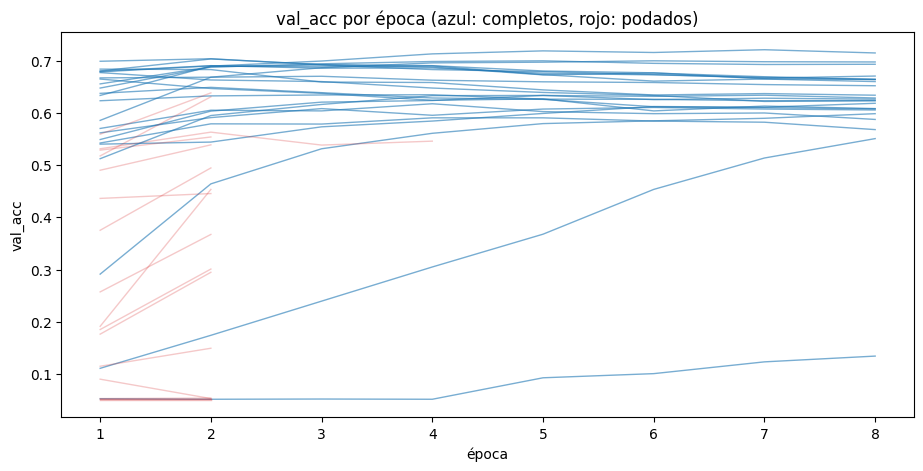

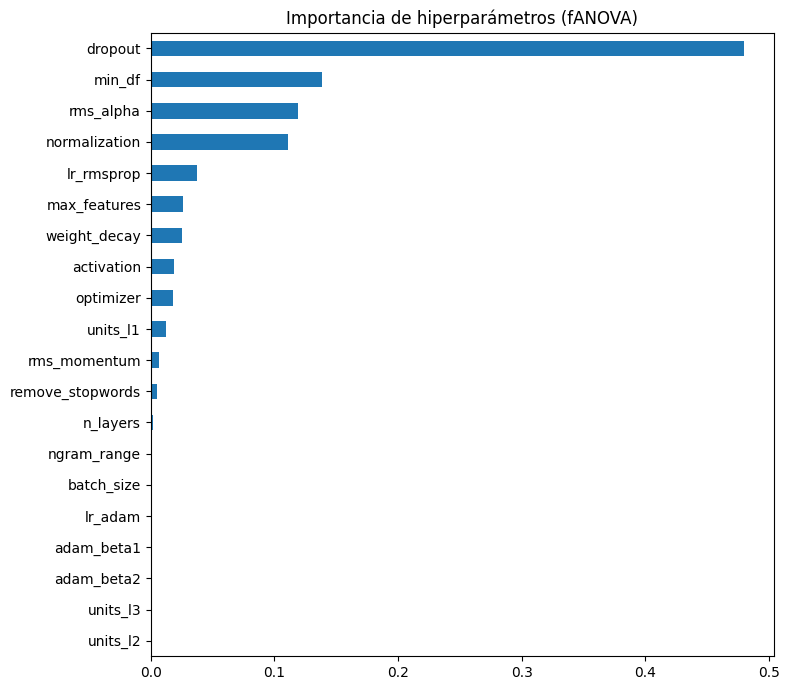

In [ ]:
# Curvas val_acc por época de todos los trials (los podados terminan antes)
fig, ax = plt.subplots(figsize=(11, 5))
for t in study.trials:
    if not t.intermediate_values: continue
    ep, v = zip(*sorted(t.intermediate_values.items()))
    pruned = t.state == optuna.trial.TrialState.PRUNED
    ax.plot(np.array(ep) + 1, v, color="tab:red" if pruned else "tab:blue", alpha=.25 if pruned else .6, lw=1)
ax.set_xlabel("época"); ax.set_ylabel("val_acc"); ax.set_title("val_acc por época (azul: completos, rojo: podados)")
plt.show()

try:
    imp = optuna.importance.get_param_importances(study)
    s = pd.Series(imp).sort_values()
    s.plot.barh(figsize=(8, 7), title="Importancia de hiperparámetros (fANOVA)")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("No se pudo calcular importancia:", e)

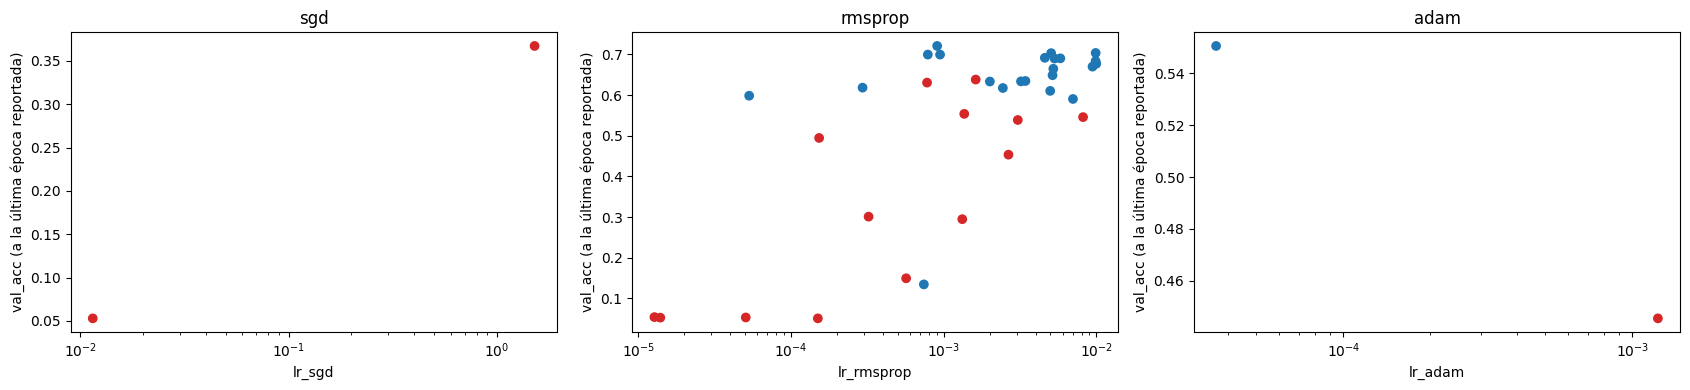

In [ ]:
# Relación entre lr y val_acc, por optimizador
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (o, col) in zip(axes, [("sgd", "lr_sgd"), ("rmsprop", "lr_rmsprop"), ("adam", "lr_adam")]):
    d = df[df.optimizer == o]
    ax.scatter(d[col], d["value"], c=np.where(d.state == "PRUNED", "tab:red", "tab:blue"))
    ax.set_xscale("log"); ax.set_xlabel(col); ax.set_ylabel("val_acc (a la última época reportada)"); ax.set_title(o)
plt.tight_layout(); plt.show()

### 5.5 Conclusiones

> Completar con los resultados obtenidos al correr la notebook. Guía de preguntas:
>
> - **Optimizadores**: ¿cuál da mejor val_acc y cuál es más robusto (menos trials podados / menor dispersión)? ¿Qué rango de lr funcionó en cada uno y por qué SGD necesita lr mucho más altos? ¿Hizo diferencia el momento de 1er orden (momentum/beta1) y el de 2do orden (alpha/beta2)?
> - **Activaciones**: ¿hay diferencias reales o están dentro de la dispersión entre trials? ¿`tanh` se comporta distinto?
> - **Profundidad y ancho**: ¿más capas/neuronas mejoran val_acc o solo aumentan train_acc (gap) y el tiempo? Comparar con la regresión softmax del TP anterior.
> - **Overfitting (sección 4)**: ¿a partir de qué tamaño (capas × neuronas, # parámetros) aparece `train_acc ≈ 1` con val_loss subiendo? ¿Qué rol tienen `dropout` y `weight_decay` en la búsqueda?
> - **Tiempo**: relación entre # parámetros, `batch_size` y tiempo por época; trade-off val_acc vs tiempo (frontera de Pareto). ¿Cuánto ahorró el pruning?
> - **Importancia de HPs**: ¿qué hiperparámetros explican más la varianza (¿optimizador y lr?, ¿preprocesamiento?).

## 6. Entrenamiento final y evaluación en test

Con los mejores HPs se reentrena con **todo** el train set, durante `best_epoch` épocas (la época donde se alcanzó la mejor val_acc en la búsqueda; así no se usa el test para decidir cuándo cortar) y recién ahí se evalúa en test.

In [ ]:
best_trial = study.best_trial
bp = best_trial.params
hidden = [bp[f"units_l{i+1}"] for i in range(bp["n_layers"])]
opt_name = bp["optimizer"]
lr = bp[f"lr_{opt_name}"]
opt_kw = {"sgd": dict(momentum=bp.get("sgd_momentum"), nesterov=bp.get("sgd_nesterov")),
          "rmsprop": dict(alpha=bp.get("rms_alpha"), momentum=bp.get("rms_momentum")),
          "adam": dict(beta1=bp.get("adam_beta1"), beta2=bp.get("adam_beta2"))}[opt_name]
EPOCHS_FINAL = int(best_trial.user_attrs["best_epoch"])
print("Arquitectura:", hidden, "| activación:", bp["activation"], "| dropout:", round(bp["dropout"], 3))
print("Optimizador:", opt_name, "| lr:", lr, "|", opt_kw, "| wd:", bp["weight_decay"])
print("Épocas finales:", EPOCHS_FINAL)

ngram_t = (1, 1) if bp["ngram_range"] == "1gram" else (1, 2)
train_texts, test_texts = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
X_train_f, X_test_f, vectorizer_final = vectorize_data(train_texts, test_texts, ngram_t, bp["max_features"], bp["min_df"])
Xtr_f, Xte_f = to_dense(X_train_f), to_dense(X_test_f)
ytr_f = torch.tensor(y_all_train, dtype=torch.long, device=device)
yte_f = torch.tensor(y_test, dtype=torch.long, device=device)

set_seed()
model = MLP(Xtr_f.shape[1], hidden, NUM_CLASSES, bp["activation"], bp["dropout"])
optimizer = build_optimizer(model.parameters(), opt_name, lr, bp["weight_decay"], **opt_kw)
hist_f, t_f = train_model(model, optimizer, Xtr_f, ytr_f, Xte_f, yte_f, EPOCHS_FINAL, bp["batch_size"], verbose=True, tag="final")
print(f"\nTiempo de entrenamiento final: {t_f:.1f}s | parámetros: {count_params(model):,}")

Arquitectura: [256] | activación: silu | dropout: 0.29
Optimizador: rmsprop | lr: 0.0009056597684546748 | {'alpha': 0.8490468695179783, 'momentum': 0.7668281579273881} | wd: 5.402202205879958e-08
Épocas finales: 7
[final] ep 01/7 train_loss 1.8779 acc 0.7113 | val_loss 2.0413 acc 0.6130 | 0.90s
[final] ep 02/7 train_loss 1.0593 acc 0.7776 | val_loss 1.3716 acc 0.6470 | 0.92s
[final] ep 03/7 train_loss 0.7335 acc 0.8281 | val_loss 1.1789 acc 0.6599 | 0.90s
[final] ep 04/7 train_loss 0.5622 acc 0.8606 | val_loss 1.1273 acc 0.6645 | 0.92s
[final] ep 05/7 train_loss 0.4457 acc 0.8882 | val_loss 1.1229 acc 0.6668 | 0.91s
[final] ep 06/7 train_loss 0.3583 acc 0.9129 | val_loss 1.1477 acc 0.6670 | 1.17s
[final] ep 07/7 train_loss 0.2941 acc 0.9291 | val_loss 1.1734 acc 0.6634 | 0.92s

Tiempo de entrenamiento final: 6.6s | parámetros: 1,285,396


Accuracy en test: 0.6634

                          precision    recall  f1-score   support

             alt.atheism       0.47      0.51      0.49       319
           comp.graphics       0.56      0.64      0.60       389
 comp.os.ms-windows.misc       0.63      0.60      0.61       394
comp.sys.ibm.pc.hardware       0.62      0.61      0.62       392
   comp.sys.mac.hardware       0.67      0.66      0.66       385
          comp.windows.x       0.78      0.64      0.70       395
            misc.forsale       0.75      0.78      0.76       390
               rec.autos       0.45      0.73      0.56       396
         rec.motorcycles       0.78      0.70      0.74       398
      rec.sport.baseball       0.87      0.79      0.83       397
        rec.sport.hockey       0.87      0.89      0.88       399
               sci.crypt       0.82      0.71      0.76       396
         sci.electronics       0.57      0.55      0.56       393
                 sci.med       0.78      0.73    

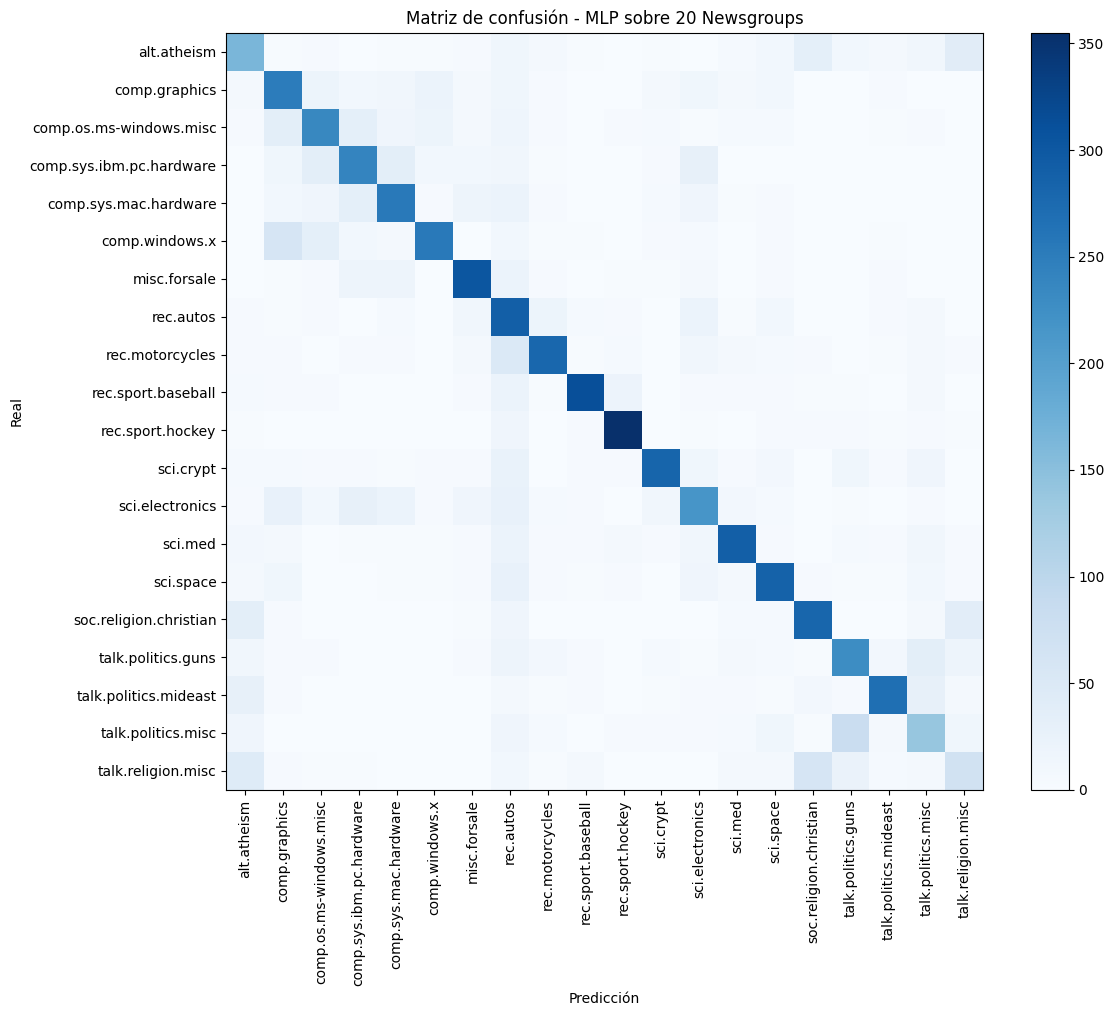

In [ ]:
model.eval()
with torch.no_grad():
    preds = torch.cat([model(Xte_f[i:i+2048]).argmax(1) for i in range(0, Xte_f.size(0), 2048)]).cpu().numpy()
print(f"Accuracy en test: {accuracy_score(y_test, preds):.4f}\n")
print(classification_report(y_test, preds, target_names=class_names))

cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión - MLP sobre 20 Newsgroups")
plt.tight_layout(); plt.show()